### Build A Basic Chatbot With Langgraph(GRAPH API)

In [2]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [3]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [4]:
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-120b")


In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023F6D866270>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023F6D866CF0>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
llm=init_chat_model("groq:openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023F6D8CB110>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023F6D8CBB10>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
# Node Functionality

def chatbot(state:State):
    print(f"-------------state-{state}")
    return {"messages":[llm.invoke(state["messages"])]}

In [9]:
graph_builder = StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

graph = graph_builder.compile()


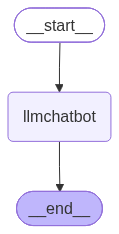

In [10]:
## visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
response=graph.invoke({"messages":"Hi"})

-------------state-{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='43667ef3-a90c-4208-b42a-f2663d3a5d36')]}


In [12]:
response['messages'][-1].content

'Hello! How can I assist you today?'

In [13]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

-------------state-{'messages': [HumanMessage(content='Hi How are you?', additional_kwargs={}, response_metadata={}, id='b11facde-b0c4-45a5-8aaa-c247dd8be420')]}
Hello! I'm doing great, thank you for asking. How can I assist you today?


### chatbot with tool


In [14]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("what is langgraph")

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [15]:
## custom function

def multiply(a:int,b:int) -> int:
    """
        Multiply a and b 

        Args:
            a (int): first int
            b (int): second int

        returns:
        int: output int
    """
    return a*b

In [16]:
tools = [tool,multiply]

In [17]:
llm_with_tool = llm.bind_tools(tools)

In [18]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023F6D8CB110>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023F6D8CBB10>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, an

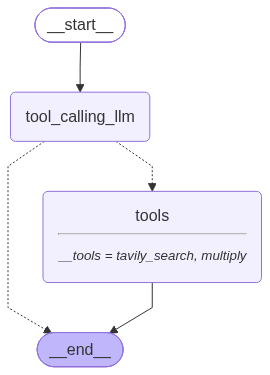

In [19]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
response = graph.invoke({"messages":"What is the recent ai news"})

In [21]:
response['messages'][-1].content

'{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=Z2Yw1f7TDrg", "title": "Top AI News 2 Nov 2026: OpenAI trims funding target", "content": "Google then released Gemini 4 Carbon, its most advanced, or frontier, model. It arrives two weeks after Gemini 4 Argon. Model prices are quoted per million tokens, and the list price is $4 per million tokens. On the security side, a modified, malicious build of Anthropic\'s Claude Code extension installed a hidden backdoor, a secret way in for attackers. Wired reports that the malicious extensions reached thousands of devices.\\n\\nFinally, the UK Competition and Markets Authority, or CMA, has opened an antitrust probe into Meta\'s content terms. Antitrust rules stop companies from abusing their market power. Each story is explained in plain language, with its source credited, so you can stay up to date on AI news in the time it takes to drink a

In [22]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_3579d10b-98b3-4a9b-82b3-21b8ba754ffb)
 Call ID: fc_3579d10b-98b3-4a9b-82b3-21b8ba754ffb
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=Z2Yw1f7TDrg", "title": "Top AI News 2 Nov 2026: OpenAI trims funding target", "content": "Google then released Gemini 4 Carbon, its most advanced, or frontier, model. It arrives two weeks after Gemini 4 Argon. Model prices are quoted per million tokens, and the list price is $4 per million tokens. On the security side, a modified, malici

In [23]:
response=graph.invoke({"messages":"What is 53647 multiplied by 73908472"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 53647 multiplied by 73908472
================================== Ai Message ==================================

The product of 53 647 and 73 908 472 is:

**3 964 967 797 384**.


In [24]:
response = graph.invoke({"messages":"mulltiply 5 by 10 and then give me the recent ai news"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

mulltiply 5 by 10 and then give me the recent ai news
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_fbc7473e-af94-49b8-ac48-6209a89be83c)
 Call ID: fc_fbc7473e-af94-49b8-ac48-6209a89be83c
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: multiply

50


### ReAct agent Architecture

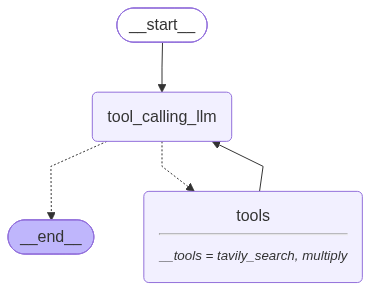

In [25]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm",tools_condition)
builder.add_edge("tools","tool_calling_llm")


graph = builder.compile()

from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
response = graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_0931cf88-d7d3-472d-9e88-36184dea1d2a)
 Call ID: fc_0931cf88-d7d3-472d-9e88-36184dea1d2a
  Args:
    query: AI news November 2026
    search_depth: advanced
    time_range: month
================================= Tool Message =================================
Name: tavily_search

{"query": "AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=1t0kdeDCHJ0", "title": "Episode 230: Weekly AI News Summary - 1 November 2026", "content": "In today’s Weekly AI News Summary.. Anthropic’s financial disclosures reveal the enormous costs of competing in the AI race, while growing concerns over AI spending, corporate debt and disappointing returns trigger a major selloff in

### Adding Memory In Agentic Graph


In [27]:
response = graph.invoke({"messages":"Hello my name is Raghul"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Raghul
================================== Ai Message ==================================

Hello Raghul! Nice to meet you. How can I assist you today?


In [28]:
response = graph.invoke({"messages":"what is my name"})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is my name
================================== Ai Message ==================================

I don’t have any information about your name. Could you let me know what you’d like me to call you?


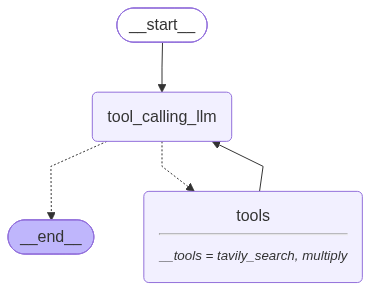

In [29]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state['messages'])]}

builder = StateGraph(State)
builder.add_node('tool_calling_llm',tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [33]:
config={"configurable":{"thread_id":"2"}}

response = graph.invoke({"messages":"Hi my name is Raghul"},config)

response

{'messages': [HumanMessage(content='Hi my name is Raghul', additional_kwargs={}, response_metadata={}, id='b99ebc7d-ca09-47ec-b514-ccc6f95460b5'),
  AIMessage(content='Hello Raghul! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Raghul". Likely a greeting. Should respond politely, maybe ask how can help. No need for tool.'}, response_metadata={'token_usage': {'completion_tokens': 59, 'prompt_tokens': 349, 'total_tokens': 408, 'completion_time': 0.123828747, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.025093805, 'prompt_tokens_details': None, 'queue_time': 0.212967952, 'total_time': 0.148922552}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_69334c0be3', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a19cf0-cbf0-7603-941f-1be9dbf549fd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 

In [34]:
response['messages'][-1].content

'Hello Raghul! Nice to meet you. How can I assist you today?'

In [35]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Yes, I remember—your name is Raghul. What would you like to talk about or work on today?


### Streaming

In [ ]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [36]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

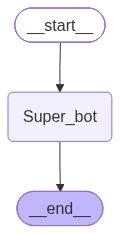

In [40]:

graph = StateGraph(State)

graph.add_node('Super_bot',superbot)
graph.add_edge(START,"Super_bot")
graph.add_edge("Super_bot",END)

graph_builder = graph.compile(checkpointer=memory)

## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [41]:
config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({"messages":"Hi, My name is Raghul and I like singing"},config)

{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='f0fd65ad-a588-439b-ae8e-a13e79aa3d56'),
  AIMessage(content='Hello Krish! Nice to meet you. How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "Hi my name is Krish". Probably a greeting. Should respond politely, maybe ask how can I help. No need for tool.'}, response_metadata={'token_usage': {'completion_tokens': 57, 'prompt_tokens': 348, 'total_tokens': 405, 'completion_time': 0.120738697, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.050357494, 'prompt_tokens_details': None, 'queue_time': 0.217864662, 'total_time': 0.171096191}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c3da0d4bb9', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a19cf0-2f37-71bf-9a46-b86ffb99f7a9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens':

#### Streaming

methods: .stream() and astream()

additional parameters in streaming nodes for graph state

- values : This streams the full state of the graph after each node is called
- updates : this streams updates to the state of the graph after each node is called

In [43]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({"messages":"Hi, my name is Raghul and i like cricket"},config,stream_mode="updates"):
    print(chunk)

{'Super_bot': {'messages': [AIMessage(content='Hey Raghul! Great to meet a fellow cricket fan. 🏏\n\nDo you have a favorite team or player? Are you more into the classic Test matches, the one‑day ODIs, or the fast‑paced T20s? And do you play the game yourself or mainly enjoy watching it? Let me know—I’d love to chat about the sport!', additional_kwargs={'reasoning_content': 'The user repeats greeting. We can respond warmly, ask about preferences. No disallowed content.'}, response_metadata={'token_usage': {'completion_tokens': 105, 'prompt_tokens': 162, 'total_tokens': 267, 'completion_time': 0.219863887, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.008093401, 'prompt_tokens_details': None, 'queue_time': 0.350417109, 'total_time': 0.227957288}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_02b0d31eca', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a19d03-445f-72f5-8809-2a89844a

In [ ]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Raghul And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, my name is Raghul and i like cricket', additional_kwargs={}, response_metadata={}, id='ccf2fd6a-47ca-4805-a2eb-90d99c7636fe'), AIMessage(content="Hello Raghul! Nice to meet you. 🎉  \nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, T20s, or maybe you enjoy playing yourself? I'd love to hear more!", additional_kwargs={'reasoning_content': 'We need to respond. The user says hi, name, likes cricket. We should greet and perhaps ask about cricket preferences. No disallowed content. Should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 83, 'total_tokens': 184, 'completion_time': 0.214532786, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.003671118, 'prompt_tokens_details': None, 'queue_time': 0.345356957, 'total_time': 0.218203904}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_60e4b492db', 'service_tier

In [47]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Raghul And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'Super_bot': {'messages': [AIMessage(content='Nice to meet you, Raghul! 👋  \n\nCricket is such a thrilling game—whether it’s the nail‑biting finishes in a T20, the tactical battles of a Test, or the excitement of a One‑Day International. Do you have a favorite team, league, or player that you follow closely? Any memorable matches that have stuck with you? I’d love to hear more about what you enjoy most about the sport!', additional_kwargs={'reasoning_content': 'The user changed name to Raghul and says they like cricket. Likely they want a response acknowledging. Should follow guidelines: respond friendly, ask about preferences. No disallowed content.'}, response_metadata={'token_usage': {'completion_tokens': 139, 'prompt_tokens': 326, 'total_tokens': 465, 'completion_time': 0.289709225, 'completion_tokens_details': {'reasoning_tokens': 39}, 'prompt_time': 0.015649355, 'prompt_tokens_details': None, 'queue_time': 0.32022545, 'total_time': 0.30535858}, 'model_name': 'openai/gpt-oss-120b

In [48]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='be2501ee-7ceb-481a-82cd-682e3a0608c9'), AIMessage(content='Hello Krish! 👋 Great to meet you.  \n\nCricket is such an exciting sport—whether you’re into batting, bowling, or just cheering from the stands. Do you have a favorite team or player? Or maybe a memorable match that’s stuck with you? I’d love to hear more!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Probably wants a response. We should greet and perhaps ask about cricket preferences. Follow guidelines: be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 109, 'prompt_tokens': 82, 'total_tokens': 191, 'completion_time': 0.229636269, 'completion_tokens_details': {'reasoning_tokens': 38}, 'prompt_time': 0.004443932, 'prompt_tokens_details': None, 'queue_time': 0.395556192, 'total_time': 0.234080201}, 'model_name': 'openai/gpt-oss-120b

In [49]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a19d05-0b53-776d-83c7-a2acb091462e', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='bf81cc03-e4b8-469e-afb8-911faf37cf92')]}}, 'name': 'Super_bot', 'tags': ['graph:step:1'], 'run_id': '01a19d05-0b54-75a6-a3e6-bcb3011e91c8', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'Super_bot', 'langgraph_triggers': ('branch:to:Super_bot',), 'langgraph_path': ('__pregel_pull', 'Super_bot'), 'langgraph_checkpoint_ns': 'Super_bot:e30156b2-5fd7-6d47-69e6-69b18fe51f54'}, 'parent_ids': ['01a19d05-0b53-776d-83c7-a2acb091462e']}
{'event': 'on_chat_model_start', 'data': {'input': {'messa